<a href="https://colab.research.google.com/github/varaprasaddalai-afk/Spotify-songs-cohorts/blob/main/Employee_Turnover_Analytics_(Dalai's).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Employee** **Turnover** **Analytics**

### Course: Machine Learning

### Student:
Dalai Siva Durga Venkat Narasimha Vara  Prasad
Or Vara Prasad Dalai

### Data Used:
HR Department Data
(HR_Comma_sep.csv)

### My Project Roadmap

**Creat the Colab Notebook**

**Upload the Project Problem Statement**

**Upload the HR_Comma_sep.csv**

Project will be completed as the follwing steps:
1. Data Quality Check
2. Correlation Heatmap
3. Satisfaction Distribution
4. Evaluation Distribution
5. Monthly-Hours Distribution
6. Project-Count Analysis
7. K-Means Clustering
8. SMOTE Class Balancing
9. Logistic Regression
10. Random Forest
11. Gradient Boosting
12. ROC/AUC Comparison
13.Confusion Matrices
14. Employee Risk Zones & Retention Strategy
15. Final Project Conclusion.

In [1]:
!pip install python-docx

from docx import Document

from google.colab import files

uploaded = files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 2.9 MB/s eta 0:00:00


Saving 1736848192_employee_turnover_problem_statement.docx to 1736848192_employee_turnover_problem_statement.docx


In [2]:
filename = list(uploaded.keys())[0]

doc = Document(filename)

for paragraph in doc.paragraphs:
    if paragraph.text.strip():
        print(paragraph.text)

Machine Learning
Course-End Project Problem Statement
Employee Turnover Analytics
Project Statement:
Portobello Tech is an app innovator who has devised an intelligent way of predicting employee turnover within the company. It periodically evaluates employees' work details, including the number of projects they worked on, average monthly working hours, time spent in the company, promotions in the last five years, and salary level.
Data from prior evaluations shows the employees’ satisfaction in the workplace. The data could be used to identify patterns in work style and their interest in continuing to work for the company. 
The HR Department owns the data and uses it to predict employee turnover. Employee turnover refers to the total number of workers who leave a company over time.
As the ML Developer assigned to the HR Department, you have been asked to create ML programs to:
Perform data quality checks by checking for missing values, if any.
Understand what factors contributed most t

**Import the required libraries**

In [3]:
# Import the Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Read the dataset
df = pd.read_csv('/content/HR_comma_sep.csv')

# Display the first 5 rows
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [5]:
# Check the number of rows and columns
df.shape

(14999, 10)

### Step1 — **Data Quality Check**

In [6]:
# Check for missing values
df.isnull().sum()

# Check the data types of all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [7]:
# Check the number of missing values in each column

df.isnull().sum()

,0
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
sales,0
salary,0


### Data Quality

***Observation***:
The dataset contains 14,999 records and 10 columns. The missing-value check shows that there are no missing values in any of the columns. Therefore, no missing-value treatment is required, and the dataset can proceed to the next stage of analysis.

### Step2 - **Exploratory Data Analysis**

2.1:- The first requirement is the correlation heatmap between all numerical features.

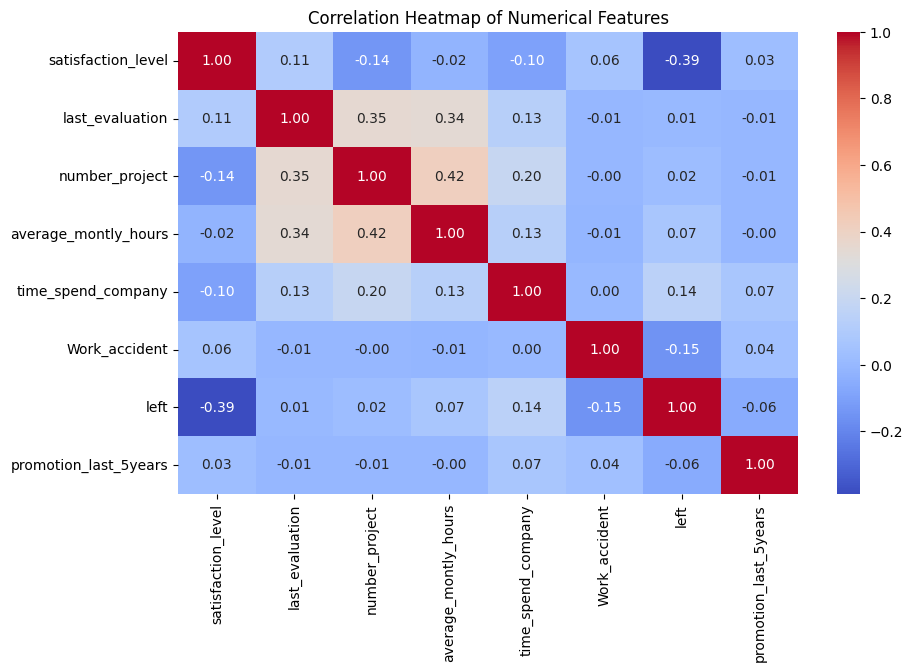

In [8]:
# Correlation matrix of numerical features

plt.figure(figsize=(10, 6))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Correlation Heatmap

***Observation***: The correlation heatmap shows that satisfaction_level has the strongest relationship with employee turnover (left), with a correlation of -0.39. This indicates that employees with lower satisfaction levels are more likely to leave the organization.

number_project and average_montly_hours show a moderate positive correlation of 0.42, while last_evaluation and number_project have a correlation of 0.35. Most of the other numerical variables have relatively weak correlations with employee turnover.

Therefore, employee satisfaction appears to be an important factor associated with employee turnover, and it should be examined further during the subsequent EDA and machine-learning analysis.

2.2:- Employee Satisfaction (satisfaction_level)

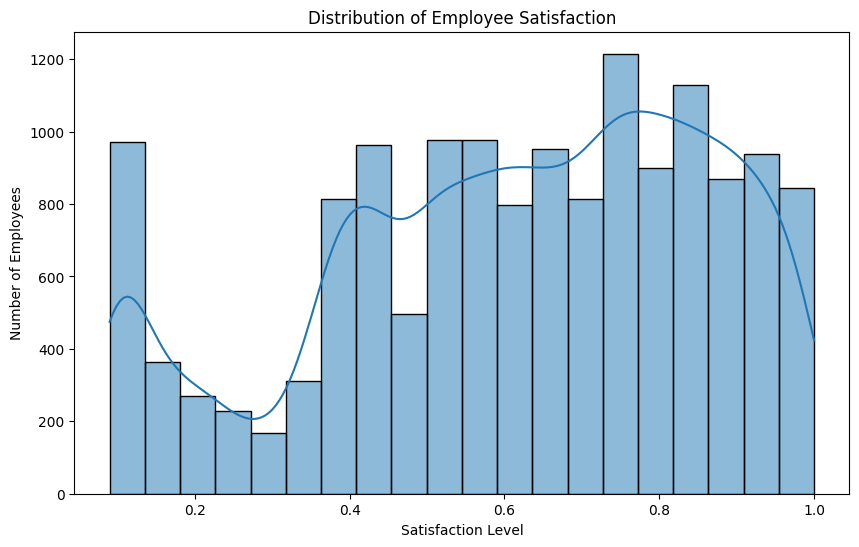

In [9]:
# Distribution of Employee Satisfaction

plt.figure(figsize=(10, 6))

sns.histplot(
    df['satisfaction_level'],
    kde=True,
    bins=20
)

plt.title('Distribution of Employee Satisfaction')
plt.xlabel('Satisfaction Level')
plt.ylabel('Number of Employees')
plt.show()

### Employee Satisfaction Distribution:-
**Observation**

The distribution of employee satisfaction levels ranges from approximately 0.1 to 1.0. A large proportion of employees have satisfaction levels above 0.5, with a noticeable concentration around 0.7–0.9. However, a smaller group of employees has very low satisfaction levels. Since low satisfaction is associated with employee turnover, these employees may require further attention in the subsequent analysis.

 2.3:- Employee Evaluation Distribution

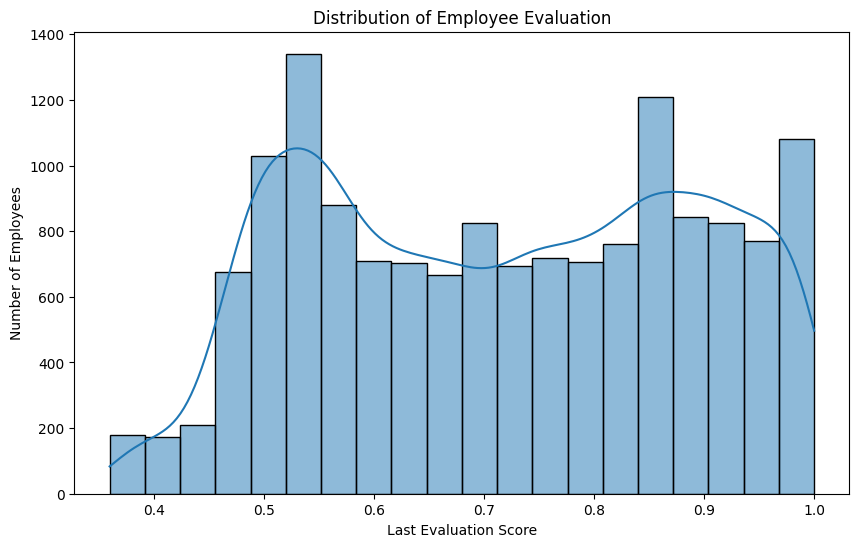

In [10]:
# Distribution of Employee Evaluation

plt.figure(figsize=(10, 6))

sns.histplot(
    df['last_evaluation'],
    kde=True,
    bins=20
)

plt.title('Distribution of Employee Evaluation')
plt.xlabel('Last Evaluation Score')
plt.ylabel('Number of Employees')
plt.show()

### Employee Evaluation Distribution

**Observation**:

The distribution of employee evaluation scores ranges approximately from 0.35 to 1.0. The scores show two noticeable concentration areas, one around 0.5–0.6 and another around 0.85–0.95. A considerable number of employees have relatively high evaluation scores, indicating that many employees received good performance ratings. Further analysis is required to determine whether evaluation scores are associated with employee turnover.

2.4:- Employee Average Monthly Hours

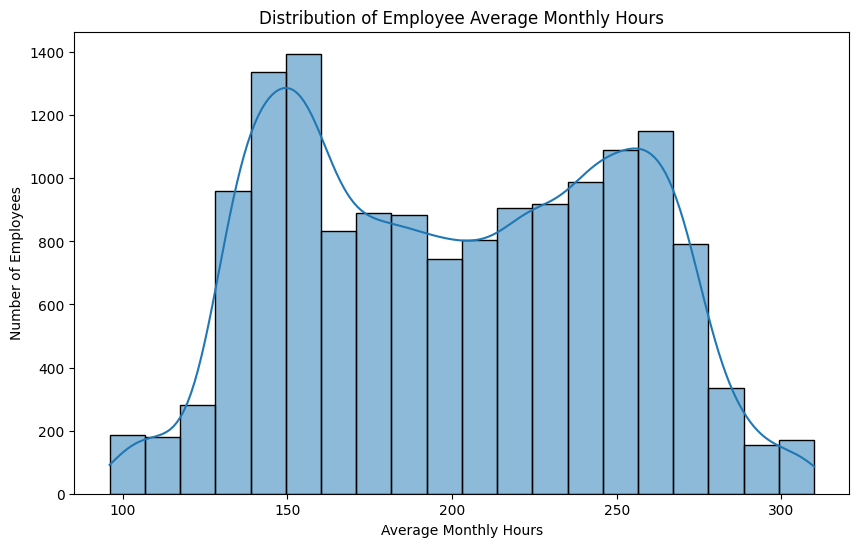

In [11]:
# Distribution of Employee Average Monthly Hours

plt.figure(figsize=(10, 6))

sns.histplot(
    df['average_montly_hours'],
    kde=True,
    bins=20
)

plt.title('Distribution of Employee Average Monthly Hours')
plt.xlabel('Average Monthly Hours')
plt.ylabel('Number of Employees')
plt.show()

2.5:— Project Count vs Employee Turnover

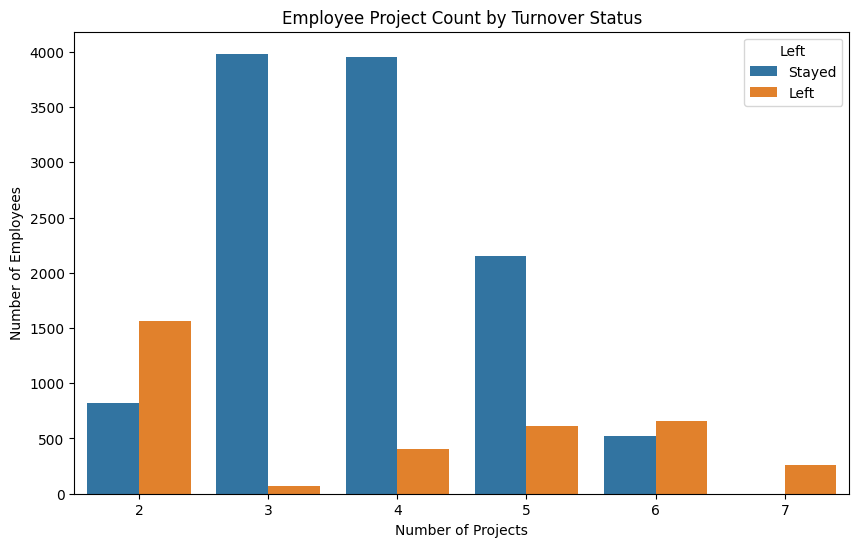

In [12]:
# Employee Project Count by Turnover Status

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='number_project',
    hue='left'
)

plt.title('Employee Project Count by Turnover Status')
plt.xlabel('Number of Projects')
plt.ylabel('Number of Employees')
plt.legend(title='Left', labels=['Stayed', 'Left'])
plt.show()

### Employee Project Count by Turnover Status

**Observation**

The bar plot shows a clear relationship between the number of projects and employee turnover. Employees with 2 projects have a high number of employees who left compared with those who stayed. Employees with 3 and 4 projects are predominantly retained. However, turnover increases again among employees handling 5, 6, and 7 projects, with employees having 6 and 7 projects showing particularly high turnover relative to the number who stayed.

This suggests that both very low project involvement and a high project workload may be associated with employee turnover. Therefore, the number of projects should be considered as an important factor in the subsequent analysis.

### Step3: - **K-Means clustering**
***Observation for 3 cells***;
Clustering employees who left the company based on satisfaction and evaluation.

*satisfaction_level*

*last_evaluation*

*left*

In [13]:
# Select  employees who left the company

left_employees = df[df['left'] == 1][['satisfaction_level', 'last_evaluation', 'left']]

left_employees.head()

,satisfaction_level,last_evaluation,left
0,0.38,0.53,1
1,0.80,0.86,1
2,0.11,0.88,1
3,0.72,0.87,1
4,0.37,0.52,1


In [14]:
# Check the number of employees who left

left_employees.shape

(3571, 3)

### Employees Who Left the Company

**Observation**:

A total of 3,571 employees are identified as having left the company. The selected dataset contains the three variables required for clustering: satisfaction level, last evaluation, and employee turnover status. Since all selected records have `left = 1`, these employees will be further grouped into three clusters based on their satisfaction level and evaluation score.

In [15]:
# K-Means Clusteringof Employees Who Left

from sklearn.cluster import KMeans

# Select satisfaction and evaluation features
X_cluster = left_employees[['satisfaction_level', 'last_evaluation']]

# Creat the K-Means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42)

# Fit the model and assign cluster labels
left_employees['cluster'] = kmeans.fit_predict(X_cluster)

# Display the cluster labels
left_employees.head()

,satisfaction_level,last_evaluation,left,cluster
0,0.38,0.53,1,0
1,0.80,0.86,1,1
2,0.11,0.88,1,2
3,0.72,0.87,1,1
4,0.37,0.52,1,0


In [16]:
# Number of employees in each cluster
left_employees['cluster'].value_counts().sort_index()

,count
cluster,
0,1650
1,977
2,944


### K-Means Cluster Distribution
**Observation**:
The K-Means algorithm has successfully grouped the 3,571 employees who left the company into three clusters. Cluster 0 contains 1,650 employees, Cluster 1 contains 977 employees, and Cluster 2 contains 944 employees. Cluster 0 is the largest cluster, while Clusters 1 and 2 contain relatively similar numbers of employees.

The cluster labels are assigned by the K-Means algorithm and do not themselves indicate whether a cluster represents high or low satisfaction or evaluation. Therefore, the characteristics of each cluster need to be examined using the cluster centers and visualization.

### Visulization

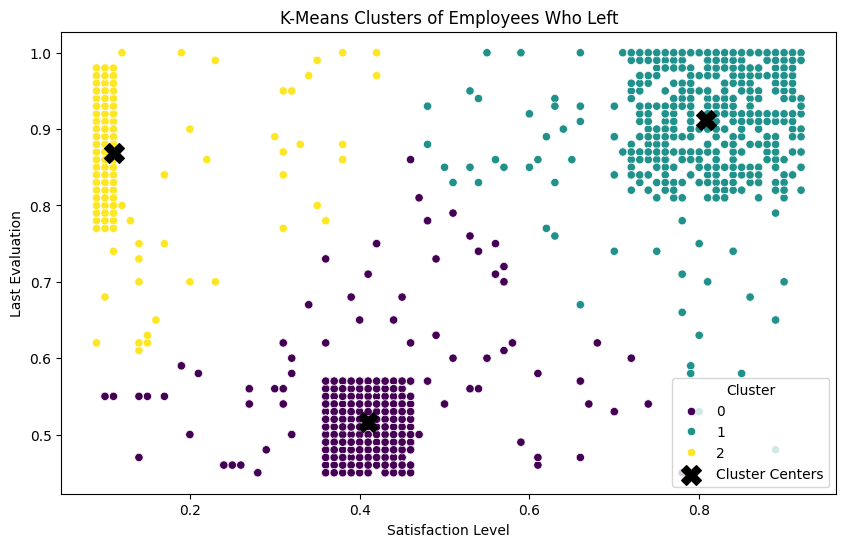

In [17]:
# Visulize the K-Means clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=left_employees,
    x='satisfaction_level',
    y='last_evaluation',
    hue='cluster',
    palette='viridis',
)

# Plot cluster centers
centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='black',
    marker='X',
    s=200,
    label='Cluster Centers'
)

plt.title('K-Means Clusters of Employees Who Left')
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.legend(title='Cluster')
plt.show()

### K-Means Employee Clusters
**Observation**:
The K-Means algorithm grouped the 3,571 employees who left the company into three distinct clusters based on satisfaction level and last evaluation.

- Cluster 0 represents employees with relatively low satisfaction and relatively low evaluation scores. Its center is approximately 0.41 satisfaction and 0.52 evaluation.
- Cluster 1 represents employees with high satisfaction and high evaluation scores. Its center is approximately 0.81 satisfaction and 0.91 evaluation.
- Cluster 2 represents employees with very low satisfaction but high evaluation scores. Its center is approximately 0.11 satisfaction and 0.87 evaluation.

The results indicate that employees who left the company show different patterns. In particular, Cluster 2 is notable because employees have very low satisfaction despite receiving high evaluation scores. Cluster 0 also shows relatively low satisfaction and evaluation. These patterns suggest that employee satisfaction and performance evaluation together can help identify different groups of employees who are at risk of turnover.

In [18]:
# Calculate the average satisfaction and evaluation for each cluster

cluster_summary = left_employees.groupby('cluster')[['satisfaction_level', 'last_evaluation']].mean().round(2)

cluster_summary

,satisfaction_level,last_evaluation
cluster,,
0,0.41,0.52
1,0.81,0.91
2,0.11,0.87


### Cluster Summary
**Observation**:
The cluster-wise averages confirm the characteristics of the three employee groups:

- Cluster 0 has an average satisfaction level of 0.41 and an average evaluation score of 0.52, indicating relatively low satisfaction and evaluation.
- Cluster 1 has an average satisfaction level of 0.81 and an average evaluation score of 0.91, indicating high satisfaction and high evaluation.
- Cluster 2 has an average satisfaction level of 0.11 and an average evaluation score of 0.87, indicating very low satisfaction despite high evaluation scores.

Among the three clusters, Cluster 2 is particularly important because employees show very low satisfaction while receiving high evaluation scores. This suggests that performance evaluation alone may not reflect employee willingness to continue with the organization.

### Step4.1 — Data Pre-processing

In [19]:
# Separate target variable from input features

X = df.drop('left', axis=1)
y = df['left']

# Separate numerical and categorical variables

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years']

Categorical Features:
['sales', 'salary']


### Observation – Data Pre-processing

The dataset contains seven numerical features and two categorical features. The numerical features include satisfaction level, last evaluation, number of projects, average monthly hours, time spent at the company, work accidents, and promotions in the last five years. The categorical features are sales and salary.

The target variable is 'left', which indicates whether an employee left the company. The categorical variables will be converted into numerical dummy variables before applying the machine-learning models and SMOTE.

### Encoding Categorical Variables

In [20]:
# Convert categorical variables into dummy variables

X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

# Display the first 5 rows
X_encoded.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False


### Step4.2 — Train-Test Split

In [21]:
# Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nTraiing target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (11999, 18)
Testing set shape: (3000, 18)

Traiing target distribution:
left
0    9142
1    2857
Name: count, dtype: int64

Testing target distribution:
left
0    2286
1     714
Name: count, dtype: int64


### Train-Test Split
**Observation**:
The dataset was divided into 80% training data and 20% testing data. The training set contains 11,999 records and the testing set contains 3,000 records, with 18 features in both sets.

The target variable is imbalanced, with 9,142 employees who stayed and 2,857 employees who left in the training data. The testing data contains 2,286 employees who stayed and 714 employees who left.

The imbalance in the training data indicates that SMOTE is required to improve the representation of the minority turnover class before model training.

In [22]:
# Apply SMOTE to balance the training data

from imblearn.over_sampling import SMOTE
import numpy as np

smote = SMOTE(random_state=42)

# Apply SMOTE
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Check class distribution before SMOTE
before_counts = np.bincount(np.asarray(y_train))

# Check class distribution after SMOTE
after_counts = np.bincount(np.asarray(y_train_smote))

print("Before SMOTE:")
print("Class 0 (Stayed):", before_counts[0])
print("Class 1 (Left):", before_counts[1])

print("\nAfter SMOTE:")
print("Class 0 (Stayed):", after_counts[0])
print("Class 1 (Left):", after_counts[1])

print("\nTraining data shape after SMOTE:")
print(X_train_smote.shape)

Before SMOTE:
Class 0 (Stayed): 9142
Class 1 (Left): 2857

After SMOTE:
Class 0 (Stayed): 9142
Class 1 (Left): 9142

Training data shape after SMOTE:
(18284, 18)


### SMOTE Class Balancing
**Observation**:
Before applying SMOTE, the training data was imbalanced, with 9,142 employees who stayed and only 2,857 employees who left.

SMOTE successfully balanced the training data by generating synthetic samples for the minority class. After SMOTE, both classes contain 9,142 records each, resulting in a balanced training dataset of 18,284 records and 18 features.

This balanced dataset will be used for training the classification models so that the minority employee-turnover class receives adequate representation during model learning.

### Step5 — Logistic Regression:

We will train Logistic Regression on the SMOTE-balanced training data and evaluate it on the original test data.


In [23]:
# Logistic Regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

# Create and train the Logistic Regression model
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

logistic_model.fit(X_train_scaled, y_train_smote)

# Make predictions on the test data
y_pred_lr = logistic_model.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

# Display the results
print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1-Score :", f1_lr)

Logistic Regression Performance
--------------------------------
Accuracy : 0.7746666666666666
Precision: 0.5188866799204771
Recall   : 0.7310924369747899
F1-Score : 0.6069767441860465


Observation: Logistic Regression achieved an accuracy of approximately 77.47%. The precision was approximately 51.89%, while recall was approximately 73.11%, indicating that the model identifies a substantial proportion of employees who left the company. The F1-score was approximately 60.70%, showing a moderate balance between precision and recall. The relatively lower precision indicates that some employees predicted as likely to leave actually stayed. Overall, Logistic Regression provides a useful baseline model for predicting employee turnover.

### Step6 — Random Forest Model


In [24]:
# Random Forest Model - Corrected

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train using SMOTE-balanced training data
rf_model.fit(X_train_smote, y_train_smote)

# Predict using the ORIGINAL unscaled test data
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

# Display results
print("Random Forest Performance")
print("-------------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1-Score :", round(f1_rf, 4))

Random Forest Performance
-------------------------
Accuracy : 0.9897
Precision: 0.99
Recall   : 0.9664
F1-Score : 0.978


### Random Forest — Observation

**Observation**: The Random Forest model achieved an accuracy of 98.97%, with a precision of 99.00%, recall of 96.64%, and an F1-score of 97.80%. These results indicate that the model performs very well in identifying employees who are likely to leave the company. The high recall shows that the model successfully detects most employees who left, while the high precision indicates very few false-positive predictions. Overall, Random Forest provides a strong predictive performance for employee turnover.

### step7 — Gradient Boosting

In [25]:
# Gradient Boosting Model

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train using SMOTE-balanced training data
gb_model.fit(X_train_smote, y_train_smote)

# Make predictions using the original unscaled test data
y_pred_gb = gb_model.predict(X_test)

# Calculate evaluation metrics
accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb, zero_division=0)
recall_gb = recall_score(y_test, y_pred_gb, zero_division=0)
f1_gb = f1_score(y_test, y_pred_gb, zero_division=0)

# Display results
print("Gradient Boosting Performance")
print("-----------------------------")
print("Accuracy :", round(accuracy_gb, 4))
print("Precision:", round(precision_gb, 4))
print("Recall   :", round(recall_gb, 4))
print("F1-Score :", round(f1_gb, 4))

Gradient Boosting Performance
-----------------------------
Accuracy : 0.965
Precision: 0.9177
Recall   : 0.937
F1-Score : 0.9272


### Gradient Boosting — Observation

**Observation**: The Gradient Boosting model achieved an accuracy of 96.50%, with a precision of 91.77%, recall of 93.70%, and an F1-score of 92.72%. The high recall indicates that the model successfully identifies most employees who are likely to leave the company. The precision is also high, showing that most predicted turnover cases are correct. The F1-score demonstrates a strong balance between precision and recall. Overall, Gradient Boosting provides strong predictive performance, although it performs slightly below the Random Forest model on these evaluation metrics.

### Step8 — ROC/AUC Model Comparison.

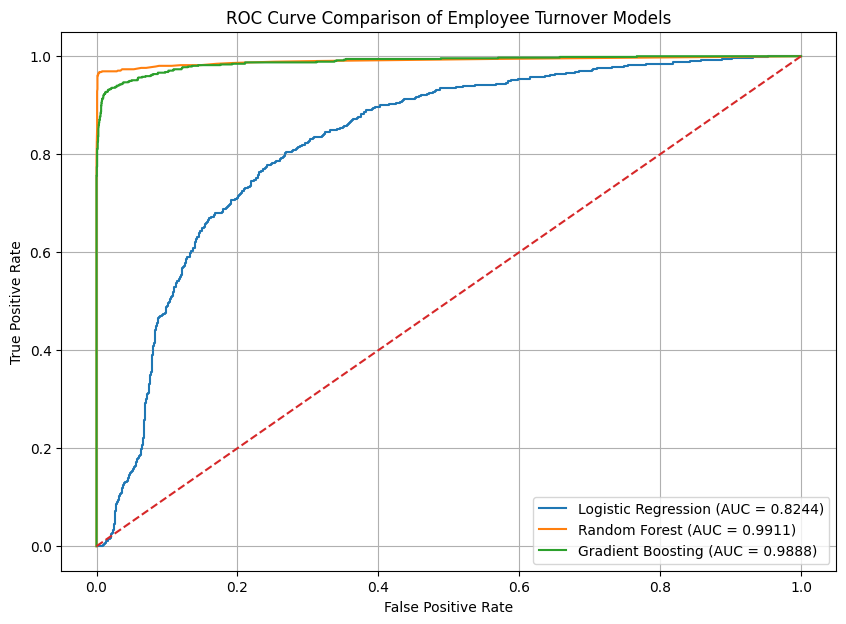

AUC Scores
----------
Logistic Regression: 0.8244
Random Forest      : 0.9911
Gradient Boosting  : 0.9888


In [26]:
# ROC Curve and AUC Comparison

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability predictions for the positive class (Left = 1)

# Logistic Regression
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Random Forest
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Gradient Boosting
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_gb)

# Calculate AUC scores
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_gb = roc_auc_score(y_test, y_prob_gb)

# Plot ROC curves
plt.figure(figsize=(10, 7))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})')
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.4f})')

# Reference line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Employee Turnover Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Display AUC scores
print("AUC Scores")
print("----------")
print("Logistic Regression:", round(auc_lr, 4))
print("Random Forest      :", round(auc_rf, 4))
print("Gradient Boosting  :", round(auc_gb, 4))

### ROC/AUC — Observation

**Observation**: The ROC/AUC comparison shows that all three models perform better than random classification, but the tree-based models provide substantially stronger discrimination. Random Forest achieved the highest AUC of 0.9911, followed closely by Gradient Boosting with an AUC of 0.9888. Logistic Regression achieved an AUC of 0.8244. Therefore, Random Forest demonstrates the best overall ability to distinguish between employees who stayed and employees who left the company.

### Step9 — Confusion Matrices: Recall vs Precision

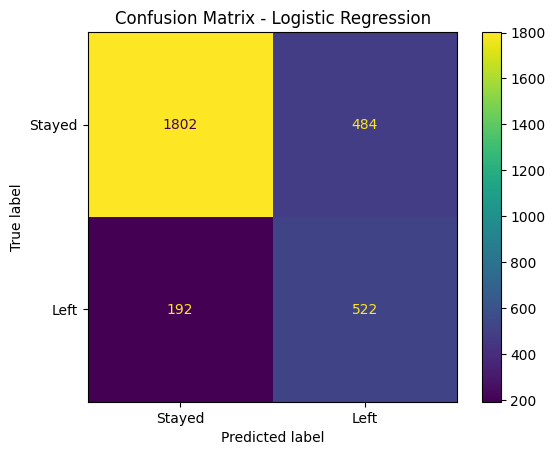

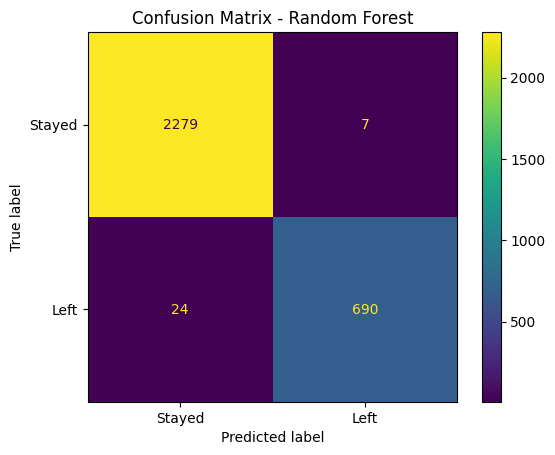

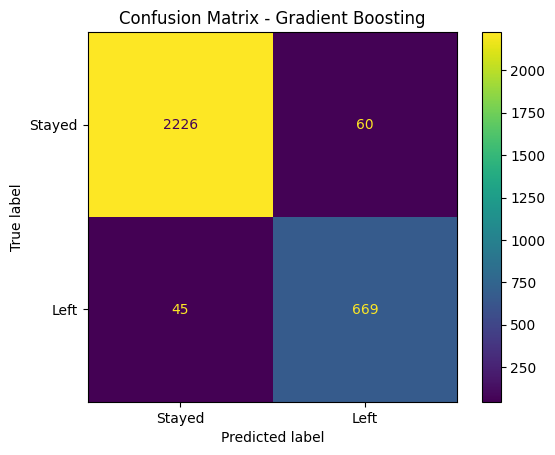

Logistic Regression Confusion Matrix:
[[1802  484]
 [ 192  522]]

Random Forest Confusion Matrix:
[[2279    7]
 [  24  690]]

Gradient Boosting Confusion Matrix:
[[2226   60]
 [  45  669]]


In [27]:
# Confusion Matrices - Model Comparison

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_gb = confusion_matrix(y_test, y_pred_gb)

# Create separate confusion matrix plots

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=['Stayed', 'Left']
)
disp_lr.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

# Random Forest
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Stayed', 'Left']
)
disp_rf.plot()
plt.title('Confusion Matrix - Random Forest')
plt.show()

# Gradient Boosting
disp_gb = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=['Stayed', 'Left']
)
disp_gb.plot()
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

# Display the confusion matrices as numbers
print("Logistic Regression Confusion Matrix:")
print(cm_lr)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

print("\nGradient Boosting Confusion Matrix:")
print(cm_gb)

**Observation**: — Confusion Matrices: Recall vs Precision
The confusion matrices show that Random Forest performs best in identifying employees who are likely to leave the company.
Logistic Regression: correctly identified 522 employees who left, but missed 192 actual turnover cases.
Random Forest: correctly identified 690 of 714 employees who left and missed only 24 cases. It also produced only 7 false positives.
Gradient Boosting: correctly identified 669 of 714 employees who left and missed 45 cases, performing better than Logistic Regression but slightly below Random Forest.
Therefore, Random Forest provides the strongest balance of precision and recall and is the most suitable model for identifying employee turnover risk.

### Step10 — Employee Risk Zones

In [28]:
# Employee Risk Zones based on Random Forest turnover probability

# Calculate probability that an employee will leave
risk_probability = rf_model.predict_proba(X_test)[:, 1]

# Define employee risk zones
risk_zone = pd.cut(
    risk_probability,
    bins=[0, 0.30, 0.60, 1.00],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True
)

# Count employees in each risk zone
risk_summary = risk_zone.value_counts().sort_index()

print("Employee Risk Zone Distribution")
print("--------------------------------")
print(risk_summary)

# Calculate percentage of employees in each risk zone
risk_percentage = (risk_summary / len(risk_zone) * 100).round(2)

print("\nRisk Zone Percentage")
print("--------------------")
print(risk_percentage)

Employee Risk Zone Distribution
--------------------------------
Low Risk       2260
Medium Risk      47
High Risk       693
Name: count, dtype: int64

Risk Zone Percentage
--------------------
Low Risk       75.33
Medium Risk     1.57
High Risk      23.10
Name: count, dtype: float64


**Observation**: — Employee Risk Zones and Retention Strategy
The Random Forest model classified the 3,000 test-set employees into three turnover-risk zones based on their predicted probability of leaving:
Low Risk: 2,260 employees (75.33%) have a predicted turnover probability below 30%, indicating relatively low immediate risk.
Medium Risk: 47 employees (1.57%) fall between 30% and 60% predicted risk and should be monitored.
High Risk: 693 employees (23.10%) have a predicted turnover probability above 60%, making them the most important group for retention efforts.
Although the majority of employees are in the Low Risk category, the 693 High Risk employees represent a significant group requiring proactive retention measures.
The organization should prioritize high-risk employees through engagement initiatives, workload review, career-development opportunities, recognition, and manager-level interventions.


### Step11 - Retention Strategy Table

In [29]:
# Retention strategy by employee risk zone

retention_strategy = pd.DataFrame({
    'Risk Zone': ['Low Risk', 'Medium Risk', 'High Risk'],
    'Employees': [
        risk_summary['Low Risk'],
        risk_summary['Medium Risk'],
        risk_summary['High Risk']
    ],
    'Percentage': [
        risk_percentage['Low Risk'],
        risk_percentage['Medium Risk'],
        risk_percentage['High Risk']
    ],
    'Recommended Retention Strategy': [
        'Maintain engagement, recognition and regular employee feedback.',
        'Monitor satisfaction, workload and career-development needs.',
        'Prioritize immediate intervention through manager discussions, career growth, recognition and workload review.'
    ]
})

retention_strategy

,Risk Zone,Employees,Percentage,Recommended Retention Strategy
0,Low Risk,2260,75.33,"Maintain engagement, recognition and regular e..."
1,Medium Risk,47,1.57,"Monitor satisfaction, workload and career-deve..."
2,High Risk,693,23.10,Prioritize immediate intervention through mana...


### Step12 - Final Project Conclusion

The Employee Turnover Analytics project analyzed employee characteristics and identified factors and patterns associated with employee turnover.

The analysis began with data-quality checks and exploratory data analysis to understand employee satisfaction, evaluation scores, working hours, project counts, and other relevant variables.

K-Means clustering of the 3,571 employees who left the company identified three distinct groups based on satisfaction and evaluation:
- Cluster 0: relatively low satisfaction and evaluation.
- Cluster 1: high satisfaction and evaluation.
- Cluster 2: very low satisfaction but high evaluation.

The classification stage addressed the imbalance in the turnover target variable using SMOTE. Three machine-learning models were then evaluated: Logistic Regression, Random Forest, and Gradient Boosting.

Based on the ROC-AUC comparison, Random Forest achieved the highest AUC of 0.9911, followed by Gradient Boosting at 0.9888 and Logistic Regression at 0.8244.

The Random Forest model also demonstrated the strongest classification performance, with an accuracy of 0.9897, precision of 0.9900, recall of 0.9664, and F1-score of 0.9780.

The employee risk-zone analysis further classified the test employees into Low, Medium, and High turnover-risk groups. The results identified 693 employees (23.10%) as High Risk, highlighting a significant group that should receive proactive retention attention.

Overall, the project demonstrates how exploratory analysis, clustering, SMOTE, and machine-learning models can be combined to identify employee turnover patterns and support data-driven employee retention strategies.